# Feature Selection and Model Interpretation

Explore unsupervised redundancy measures, supervised rankings, wrapper methods and embedded feature selection. Preserve the original estimators and parameter configurations.

**References:** [scikit-learn feature selection](https://scikit-learn.org/stable/modules/feature_selection.html), [mlxtend](https://rasbt.github.io/mlxtend/), [Feature-engine](https://feature-engine.trainindata.com/).

In [1]:
# Environment setup: install the packages used by this notebook in the selected kernel.
!pip install feature_engine
!pip install mlxtend
!pip install sklearn-genetic-opt

In [2]:
# Load the numerical, visualization, and machine-learning utilities for this workflow.
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import plotly.express as px
%matplotlib inline

from sklearn.tree import DecisionTreeClassifier, plot_tree, export_graphviz
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import ComplementNB
from sklearn.svm import SVC
import missingno as msno

from sklearn.model_selection import train_test_split, cross_validate, cross_val_predict
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import LabelEncoder, OrdinalEncoder,StandardScaler

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer


import utils as ad

## 1. Reduce redundant measurements

Use sonar signals to inspect correlation among predictors without consulting the class label. Redundancy and predictive relevance are different questions.

In [3]:
# Load the project dataset from its local data directory and inspect its schema.
# Load sonar data.
sonar = pd.read_csv('data/sonar_signal_profiles.csv', sep=';')
sonar.info()

<class 'pandas.DataFrame'>
RangeIndex: 208 entries, 0 to 207
Data columns (total 61 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   f04_sonar_band_01         208 non-null    float64
 1   f15_sonar_band_02         208 non-null    float64
 2   f26_sonar_band_03         208 non-null    float64
 3   f37_sonar_band_04         208 non-null    float64
 4   f48_sonar_band_05         208 non-null    float64
 5   f59_sonar_band_06         208 non-null    float64
 6   f61_sonar_band_07         208 non-null    float64
 7   f62_sonar_band_08         208 non-null    float64
 8   f63_sonar_band_09         208 non-null    float64
 9   f05_sonar_band_10         208 non-null    float64
 10  f06_sonar_band_11         208 non-null    float64
 11  f07_sonar_band_12         208 non-null    float64
 12  f08_sonar_band_13         208 non-null    float64
 13  f09_sonar_band_14         208 non-null    float64
 14  f10_sonar_band_15    

In [4]:
# Separate predictors from the target using the original column-selection rule.
# 1. generate correlations (without the label column).
correlation = sonar[sonar.columns.difference(['f64_sonar_material_class'])].corr()
correlation

,f04_sonar_band_01,f05_sonar_band_10,f06_sonar_band_11,f07_sonar_band_12,f08_sonar_band_13,f09_sonar_band_14,f10_sonar_band_15,f11_sonar_band_16,f12_sonar_band_17,f13_sonar_band_18,...,f54_sonar_band_55,f55_sonar_band_56,f56_sonar_band_57,f57_sonar_band_58,f58_sonar_band_59,f59_sonar_band_06,f60_sonar_band_60,f61_sonar_band_07,f62_sonar_band_08,f63_sonar_band_09
f04_sonar_band_01,1.000000,0.318276,0.344058,0.210861,0.210722,0.256278,0.304878,0.239079,0.137845,0.041817,...,0.312067,0.220642,0.313725,0.368132,0.357116,0.238921,0.347078,0.260815,0.355523,0.353420
f05_sonar_band_10,0.318276,1.000000,0.853140,0.485392,0.405370,0.345684,0.294699,0.242869,0.121264,0.063745,...,0.175254,0.151889,0.140327,0.212277,0.058273,0.288621,0.097358,0.425448,0.652525,0.877131
f06_sonar_band_11,0.344058,0.853140,1.000000,0.781164,0.646978,0.460504,0.356516,0.304069,0.237679,0.191567,...,0.228991,0.122332,0.103405,0.193358,0.067726,0.333570,0.089695,0.396588,0.584583,0.728063
f07_sonar_band_12,0.210861,0.485392,0.781164,1.000000,0.827106,0.467793,0.281758,0.245383,0.250611,0.241910,...,0.164590,0.115658,0.030732,0.065273,0.044614,0.344451,0.071364,0.274432,0.328329,0.363404
f08_sonar_band_13,0.210722,0.405370,0.646978,0.827106,1.000000,0.756758,0.530892,0.465977,0.438185,0.394510,...,0.272492,0.183743,0.057870,0.171140,0.151804,0.411107,0.061411,0.365391,0.322951,0.316899
f09_sonar_band_14,0.256278,0.345684,0.460504,0.467793,0.756758,1.000000,0.869733,0.747277,0.636990,0.560637,...,0.326821,0.252166,0.190886,0.258675,0.209122,0.396233,0.120966,0.409576,0.387114,0.329659
f10_sonar_band_15,0.304878,0.294699,0.356516,0.281758,0.530892,0.869733,1.000000,0.912625,0.749942,0.632139,...,0.261822,0.218395,0.202511,0.225545,0.193671,0.367908,0.171089,0.411692,0.391514,0.299575
f11_sonar_band_16,0.239079,0.242869,0.304069,0.245383,0.465977,0.747277,0.912625,1.000000,0.899234,0.774855,...,0.240968,0.215478,0.191736,0.198019,0.182337,0.353783,0.158438,0.363086,0.322237,0.241819
f12_sonar_band_17,0.137845,0.121264,0.237679,0.250611,0.438185,0.636990,0.749942,0.899234,1.000000,0.925836,...,0.168460,0.128968,0.145708,0.148563,0.121800,0.293190,0.093992,0.250024,0.140912,0.100146
f13_sonar_band_18,0.041817,0.063745,0.191567,0.241910,0.394510,0.560637,0.632139,0.774855,0.925836,1.000000,...,0.093767,0.080812,0.056930,0.096022,0.028446,0.235778,0.046617,0.208057,0.061333,0.027380


In [5]:
# Inspect or update the intermediate result produced by the preceding step.
# 2. square each correlation.
sq_correlation = correlation * correlation
sq_correlation

,f04_sonar_band_01,f05_sonar_band_10,f06_sonar_band_11,f07_sonar_band_12,f08_sonar_band_13,f09_sonar_band_14,f10_sonar_band_15,f11_sonar_band_16,f12_sonar_band_17,f13_sonar_band_18,...,f54_sonar_band_55,f55_sonar_band_56,f56_sonar_band_57,f57_sonar_band_58,f58_sonar_band_59,f59_sonar_band_06,f60_sonar_band_60,f61_sonar_band_07,f62_sonar_band_08,f63_sonar_band_09
f04_sonar_band_01,1.000000,0.101299,0.118376,0.044462,0.044404,0.065678,0.092951,0.057159,0.019001,0.001749,...,9.738609e-02,0.048683,0.098423,0.135521,0.127532,0.057083,0.120463,0.068024,0.126397,0.124906
f05_sonar_band_10,0.101299,1.000000,0.727848,0.235605,0.164325,0.119497,0.086847,0.058986,0.014705,0.004063,...,3.071406e-02,0.023070,0.019692,0.045061,0.003396,0.083302,0.009479,0.181006,0.425789,0.769358
f06_sonar_band_11,0.118376,0.727848,1.000000,0.610217,0.418581,0.212064,0.127104,0.092458,0.056491,0.036698,...,5.243697e-02,0.014965,0.010693,0.037387,0.004587,0.111269,0.008045,0.157282,0.341738,0.530075
f07_sonar_band_12,0.044462,0.235605,0.610217,1.000000,0.684105,0.218831,0.079388,0.060213,0.062806,0.058520,...,2.708989e-02,0.013377,0.000944,0.004261,0.001990,0.118647,0.005093,0.075313,0.107800,0.132063
f08_sonar_band_13,0.044404,0.164325,0.418581,0.684105,1.000000,0.572682,0.281846,0.217134,0.192006,0.155638,...,7.425206e-02,0.033761,0.003349,0.029289,0.023044,0.169009,0.003771,0.133510,0.104297,0.100425
f09_sonar_band_14,0.065678,0.119497,0.212064,0.218831,0.572682,1.000000,0.756435,0.558424,0.405756,0.314314,...,1.068120e-01,0.063588,0.036438,0.066913,0.043732,0.157001,0.014633,0.167753,0.149857,0.108675
f10_sonar_band_15,0.092951,0.086847,0.127104,0.079388,0.281846,0.756435,1.000000,0.832885,0.562414,0.399600,...,6.855091e-02,0.047696,0.041011,0.050871,0.037508,0.135356,0.029271,0.169490,0.153284,0.089745
f11_sonar_band_16,0.057159,0.058986,0.092458,0.060213,0.217134,0.558424,0.832885,1.000000,0.808621,0.600400,...,5.806543e-02,0.046431,0.036763,0.039212,0.033247,0.125162,0.025103,0.131831,0.103837,0.058476
f12_sonar_band_17,0.019001,0.014705,0.056491,0.062806,0.192006,0.405756,0.562414,0.808621,1.000000,0.857172,...,2.837881e-02,0.016633,0.021231,0.022071,0.014835,0.085960,0.008834,0.062512,0.019856,0.010029
f13_sonar_band_18,0.001749,0.004063,0.036698,0.058520,0.155638,0.314314,0.399600,0.600400,0.857172,1.000000,...,8.792221e-03,0.006531,0.003241,0.009220,0.000809,0.055591,0.002173,0.043288,0.003762,0.000750


In [6]:
# Inspect or update the intermediate result produced by the preceding step.
# 3. add the results.
sq_correlation_sum = sq_correlation.sum()
sq_correlation_sum

f04_sonar_band_01    5.377761
f05_sonar_band_10    5.123597
f06_sonar_band_11    5.675621
f07_sonar_band_12    4.276248
f08_sonar_band_13    5.772365
f09_sonar_band_14    7.457322
f10_sonar_band_15    7.756554
f11_sonar_band_16    7.901611
f12_sonar_band_17    7.458724
f13_sonar_band_18    7.695458
f14_sonar_band_19    7.716611
f15_sonar_band_02    6.190148
f16_sonar_band_20    7.060479
f17_sonar_band_21    6.449632
f18_sonar_band_22    6.282001
f19_sonar_band_23    5.570997
f20_sonar_band_24    5.420957
f21_sonar_band_25    5.843045
f22_sonar_band_26    6.006612
f23_sonar_band_27    5.930497
f24_sonar_band_28    5.515436
f25_sonar_band_29    5.910035
f26_sonar_band_03    5.691548
f27_sonar_band_30    5.780751
f28_sonar_band_31    5.971626
f29_sonar_band_32    5.895640
f30_sonar_band_33    6.494642
f31_sonar_band_34    6.535655
f32_sonar_band_35    6.466947
f33_sonar_band_36    6.344590
f34_sonar_band_37    5.709412
f35_sonar_band_38    6.755099
f36_sonar_band_39    6.485521
f37_sonar_

In [7]:
# Inspect or update the intermediate result produced by the preceding step.
# 4. scale results within [0, 1].
sq_correlation_sum_scaled = (sq_correlation_sum - sq_correlation_sum.min()) / (sq_correlation_sum.max() - sq_correlation_sum.min())
sq_correlation_sum_scaled

f04_sonar_band_01    0.385369
f05_sonar_band_10    0.323473
f06_sonar_band_11    0.457907
f07_sonar_band_12    0.117119
f08_sonar_band_13    0.481467
f09_sonar_band_14    0.891803
f10_sonar_band_15    0.964674
f11_sonar_band_16    1.000000
f12_sonar_band_17    0.892144
f13_sonar_band_18    0.949796
f14_sonar_band_19    0.954947
f15_sonar_band_02    0.583209
f16_sonar_band_20    0.795160
f17_sonar_band_21    0.646401
f18_sonar_band_22    0.605578
f19_sonar_band_23    0.432428
f20_sonar_band_24    0.395889
f21_sonar_band_25    0.498679
f22_sonar_band_26    0.538513
f23_sonar_band_27    0.519976
f24_sonar_band_28    0.418897
f25_sonar_band_29    0.514993
f26_sonar_band_03    0.461786
f27_sonar_band_30    0.483509
f28_sonar_band_31    0.529993
f29_sonar_band_32    0.511488
f30_sonar_band_33    0.657362
f31_sonar_band_34    0.667350
f32_sonar_band_35    0.650618
f33_sonar_band_36    0.620820
f34_sonar_band_37    0.466136
f35_sonar_band_38    0.720791
f36_sonar_band_39    0.655141
f37_sonar_

In [8]:
# Inspect or update the intermediate result produced by the preceding step.
# 5. invert the results.
weights = 1 - sq_correlation_sum_scaled
# Optionally display them in descending order.
weights.sort_values(ascending=False)

f56_sonar_band_57    1.000000
f60_sonar_band_60    0.997248
f52_sonar_band_53    0.978548
f55_sonar_band_56    0.945673
f53_sonar_band_54    0.887713
f07_sonar_band_12    0.882881
f59_sonar_band_06    0.880362
f61_sonar_band_07    0.858837
f51_sonar_band_52    0.792536
f54_sonar_band_55    0.789617
f48_sonar_band_05    0.773742
f50_sonar_band_51    0.720206
f57_sonar_band_58    0.710411
f49_sonar_band_50    0.699456
f05_sonar_band_10    0.676527
f58_sonar_band_59    0.667745
f63_sonar_band_09    0.663577
f62_sonar_band_08    0.617070
f04_sonar_band_01    0.614631
f20_sonar_band_24    0.604111
f37_sonar_band_04    0.591165
f24_sonar_band_28    0.581103
f19_sonar_band_23    0.567572
f06_sonar_band_11    0.542093
f26_sonar_band_03    0.538214
f34_sonar_band_37    0.533864
f08_sonar_band_13    0.518533
f27_sonar_band_30    0.516491
f21_sonar_band_25    0.501321
f29_sonar_band_32    0.488512
f25_sonar_band_29    0.485007
f23_sonar_band_27    0.480024
f28_sonar_band_31    0.470007
f22_sonar_

## 2. Rank features by their relationship with the target

Introduce a linear support-vector classifier and compare feature-ranking approaches that use outcome information.

In [9]:
# Create the predefined training and validation partitions without changing split parameters.
# Separate the reg.attr. from the label attr.
X = sonar[sonar.columns.difference(['f64_sonar_material_class'])]
y = sonar[['f64_sonar_material_class']]
# Split the data.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

In [10]:
# Evaluate the current estimator using the configured cross-validation strategy.
# Model baseline using a linear SVM.
svm_clf = SVC(kernel='linear', random_state=43)
# Crossvalidate on the train portion using the custom function.
ad.report_classification_cv(X_train, y_train, svm_clf)
y_pred = svm_clf.predict(X_test)
print(classification_report(y_test, y_pred))

Mean Accuracy is 80.75 +/- 6.71
Mean Precision is 81.67 +/- 6.79
Mean Recall is 79.75 +/- 6.91
Mean F-score is 80.05 +/- 7.00
              precision    recall  f1-score   support

        Mine       0.70      0.80      0.74        20
        Rock       0.79      0.68      0.73        22

    accuracy                           0.74        42
   macro avg       0.74      0.74      0.74        42
weighted avg       0.74      0.74      0.74        42



### Filter-based feature ranking

Consider ANOVA F statistics, chi-squared scores and mutual-information criteria. Their assumptions differ, so rankings should be interpreted in the context of variable type and preprocessing.

In [11]:
# Load the numerical, visualization, and machine-learning utilities for this workflow.
from sklearn.feature_selection import GenericUnivariateSelect

"""
function to get the weights and p-values of each feature
using one of the univariate approaches;
it takes in the regular attributes data, the f64_sonar_material_class label columns,
the weighting strategy and the selection mode;
it then looks at all features and returns the weights and p-values in a dataframe
"""
def feature_ranking(X, y, strategy, mode):
  X_selected = GenericUnivariateSelect(strategy, mode=mode, param='all').fit(X, y)
  # Calculate or display the configured quality metric.
  scores = pd.DataFrame(X_selected.scores_)
  columns = pd.DataFrame(X.columns)
  attr_scores = pd.concat([columns, scores], axis=1)
  attr_scores.columns = ['attribute', 'weight']
  attr_scores['p-value'] = X_selected.pvalues_
  return attr_scores

In [12]:
# Continue the analysis using the original transformation and model parameters.
# 1. using the f-classif weighting strategy.
# We will use k_best which by default is set to all features.
from sklearn.feature_selection import f_classif
anova_scores = feature_ranking(X_train, y_train, f_classif, 'k_best')
anova_scores.sort_values(by='weight', ascending=False)


,attribute,weight,p-value
2,f06_sonar_band_11,33.042057,4.293601e-08
3,f07_sonar_band_12,27.773696,4.242737e-07
43,f47_sonar_band_49,23.339821,3.096550e-06
46,f50_sonar_band_51,22.234733,5.129274e-06
39,f43_sonar_band_45,22.047722,5.588745e-06
47,f51_sonar_band_52,20.531252,1.125350e-05
40,f44_sonar_band_46,20.055577,1.403876e-05
1,f05_sonar_band_10,17.884268,3.891768e-05
42,f46_sonar_band_48,17.102129,5.643078e-05
41,f45_sonar_band_47,16.747873,6.682590e-05


In [13]:
# Inspect or update the intermediate result produced by the preceding step.
9.899392e-01

0.9899392

30


<Axes: xlabel='attribute', ylabel='weight'>

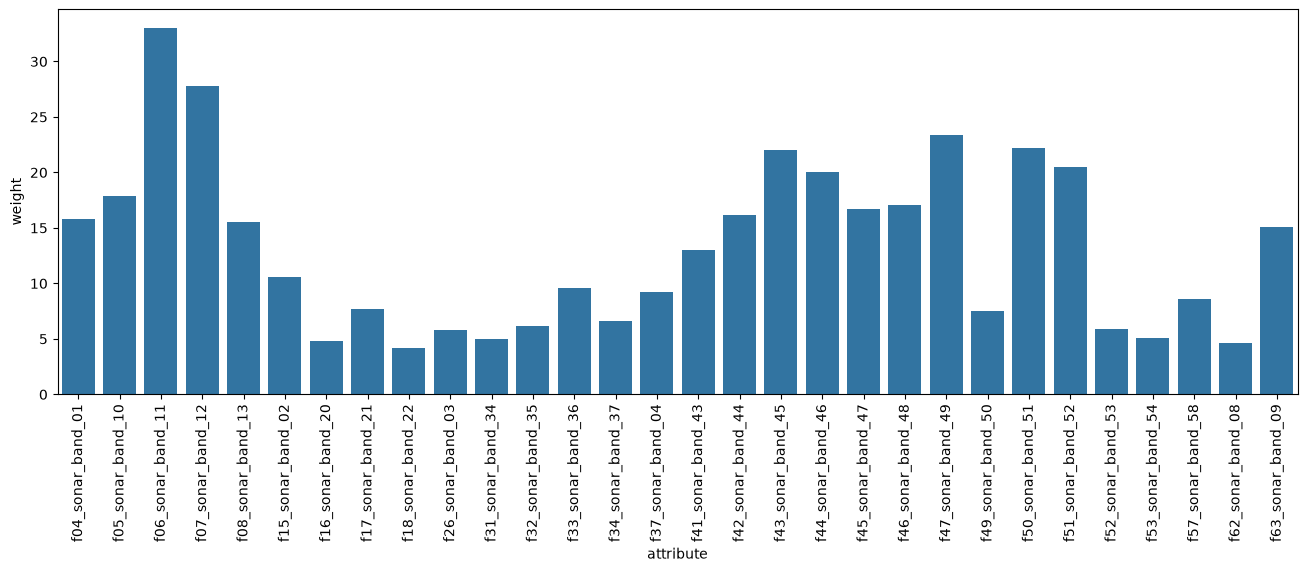

In [14]:
# Visualize the current measurements or fitted results for interpretation.
# Get the attributes for which p-values are below 0.05.
low_p_attr = anova_scores[anova_scores['p-value'] < 0.05]
print(len(low_p_attr))
# Visualize the data or model output for this comparison.
fig, ax = plt.subplots(figsize=(16, 5))
plt.xticks(rotation=90)
sns.barplot(low_p_attr, x="attribute", y="weight", ax=ax)

In [15]:
# Evaluate the current estimator using the configured cross-validation strategy.
# We can then use only those attributes in the model.
ad.report_classification_cv(X_train[list(low_p_attr.attribute)], y_train, svm_clf)
y_pred = svm_clf.predict(X_test[list(low_p_attr.attribute)])
print(classification_report(y_test, y_pred))

Mean Accuracy is 80.12 +/- 7.31
Mean Precision is 81.06 +/- 6.99
Mean Recall is 79.39 +/- 7.67
Mean F-score is 79.45 +/- 7.65
              precision    recall  f1-score   support

        Mine       0.69      0.90      0.78        20
        Rock       0.88      0.64      0.74        22

    accuracy                           0.76        42
   macro avg       0.78      0.77      0.76        42
weighted avg       0.79      0.76      0.76        42



In [16]:
# Inspect or update the intermediate result produced by the preceding step.
# Optional comparison: review this configuration against the original baseline.

### Apply selection inside cross-validation

Place feature selection inside the pipeline to fit it separately in each training fold. This prevents validation records from influencing the selected feature set.

In [17]:
# Load the numerical, visualization, and machine-learning utilities for this workflow.
from sklearn.feature_selection import SelectPercentile
from sklearn.feature_selection import chi2
prep = SelectPercentile(chi2, percentile=75)
ad.evaluate_pipeline_cv(svm_clf, prep, X_train, y_train)


Mean Accuracy is 78.36 +/- 8.04
Mean Precision is 78.64 +/- 8.09
Mean Recall is 77.56 +/- 8.42
Mean F-score is 77.69 +/- 8.48


In [18]:
# Load the numerical, visualization, and machine-learning utilities for this workflow.
# Or we can search for optimal set of hyperparameters within a range.
from sklearn.feature_selection import mutual_info_classif
params = {
    'rank__score_func': [f_classif, chi2, mutual_info_classif],
    'rank__mode': ['k_best', 'percentile'],
}
pipeline = Pipeline([
    ('rank', GenericUnivariateSelect()),
    ('classifier', svm_clf)
])
grid = GridSearchCV(pipeline, param_grid=params)
grid.fit(X_train, y_train)
grid.best_params_

{'rank__mode': 'percentile',
 'rank__score_func': <function sklearn.feature_selection._mutual_info.mutual_info_classif(X, y, *, discrete_features='auto', n_neighbors=3, copy=True, random_state=None, n_jobs=None)>}

In [19]:
# Inspect or update the intermediate result produced by the preceding step.
# Optional comparison: review this configuration against the original baseline.

# Optional comparison: review this configuration against the original baseline.
# The corresponding univariate strategies you can try are r_regression, f_regression, and mutual_info_regression.

## 3. Wrapper search

Compare forward and backward sequential selection. Wrapper search repeatedly fits the estimator, so its computational cost grows with feature count and candidate combinations.

In [20]:
# Inspect or update the intermediate result produced by the preceding step.
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn_genetic import GAFeatureSelectionCV

In [21]:
# Inspect the current dataframe to confirm its structure and values.
# 1. forward FS with svm, but it can be done with any classification algorithm.
seq_ffs = SequentialFeatureSelector(svm_clf)
forward_X = seq_ffs.fit_transform(X_train, y_train)
forward_X = pd.DataFrame(forward_X, columns=seq_ffs.get_feature_names_out())
forward_X.head()

,f04_sonar_band_01,f06_sonar_band_11,f07_sonar_band_12,f09_sonar_band_14,f10_sonar_band_15,f11_sonar_band_16,f15_sonar_band_02,f16_sonar_band_20,f20_sonar_band_24,f21_sonar_band_25,...,f52_sonar_band_53,f53_sonar_band_54,f54_sonar_band_55,f55_sonar_band_56,f56_sonar_band_57,f57_sonar_band_58,f58_sonar_band_59,f59_sonar_band_06,f60_sonar_band_60,f61_sonar_band_07
0,0.0139,0.1261,0.0828,0.0848,0.1514,0.1396,0.0222,0.3247,0.8757,0.9048,...,0.0072,0.0113,0.0012,0.0022,0.0025,0.0059,0.0039,0.0136,0.0048,0.0659
1,0.0411,0.1370,0.1335,0.1526,0.0775,0.1196,0.0277,0.2975,0.3202,0.3452,...,0.0038,0.0019,0.0065,0.0132,0.0108,0.0050,0.0085,0.0385,0.0044,0.0611
2,0.0731,0.1739,0.3160,0.2164,0.2031,0.2580,0.1249,0.1810,0.9757,0.8079,...,0.0230,0.0290,0.0141,0.0161,0.0177,0.0194,0.0207,0.2770,0.0057,0.2555
3,0.0116,0.3171,0.2882,0.2307,0.1889,0.1791,0.0744,0.7260,0.9173,0.9327,...,0.0103,0.0100,0.0034,0.0026,0.0037,0.0044,0.0057,0.0545,0.0035,0.1110
4,0.0378,0.3135,0.3118,0.3885,0.5850,0.7868,0.0318,0.8610,0.4033,0.5946,...,0.0044,0.0078,0.0102,0.0065,0.0061,0.0062,0.0043,0.1635,0.0053,0.0887


In [22]:
# Evaluate the current estimator using the configured cross-validation strategy.
ad.report_classification_cv(forward_X, y_train, svm_clf)
y_pred = svm_clf.predict(X_test[forward_X.columns])
print(classification_report(y_test, y_pred))

Mean Accuracy is 78.95 +/- 5.59
Mean Precision is 80.23 +/- 5.59
Mean Recall is 77.75 +/- 5.89
Mean F-score is 78.00 +/- 6.02
              precision    recall  f1-score   support

        Mine       0.68      0.85      0.76        20
        Rock       0.82      0.64      0.72        22

    accuracy                           0.74        42
   macro avg       0.75      0.74      0.74        42
weighted avg       0.76      0.74      0.74        42



In [23]:
# Inspect the current dataframe to confirm its structure and values.
# 2. backwards FS with svm.
seq_bfs = SequentialFeatureSelector(svm_clf, direction='backward')
backward_X = seq_bfs.fit_transform(X_train, y_train)
backward_X = pd.DataFrame(backward_X, columns=seq_bfs.get_feature_names_out())
backward_X.head()

,f05_sonar_band_10,f06_sonar_band_11,f07_sonar_band_12,f10_sonar_band_15,f16_sonar_band_20,f17_sonar_band_21,f18_sonar_band_22,f20_sonar_band_24,f22_sonar_band_26,f23_sonar_band_27,...,f40_sonar_band_42,f41_sonar_band_43,f42_sonar_band_44,f44_sonar_band_46,f45_sonar_band_47,f46_sonar_band_48,f47_sonar_band_49,f48_sonar_band_05,f62_sonar_band_08,f63_sonar_band_09
0,0.1015,0.1261,0.0828,0.1514,0.3247,0.3797,0.5658,0.8757,0.7511,0.6858,...,0.2112,0.1513,0.1789,0.1717,0.0898,0.0656,0.0445,0.0215,0.0954,0.0786
1,0.2300,0.1370,0.1335,0.0775,0.2975,0.2836,0.3353,0.3202,0.3562,0.3892,...,0.3492,0.2662,0.3137,0.4262,0.3511,0.2458,0.1259,0.0489,0.1117,0.1237
2,0.1114,0.1739,0.3160,0.2031,0.1810,0.2604,0.6572,0.9757,0.6521,0.4915,...,0.4463,0.3178,0.0807,0.2134,0.3241,0.2945,0.1474,0.1443,0.1712,0.0466
3,0.2271,0.3171,0.2882,0.1889,0.7260,0.7934,0.8045,0.9173,0.9562,1.0000,...,0.0469,0.1476,0.1742,0.1651,0.1181,0.0720,0.0321,0.0076,0.1069,0.1708
4,0.2053,0.3135,0.3118,0.5850,0.8610,0.8443,0.9061,0.4033,0.6793,0.6389,...,0.2714,0.1713,0.0584,0.2200,0.2198,0.1074,0.0423,0.1787,0.0817,0.1779


In [24]:
# Evaluate the current estimator using the configured cross-validation strategy.
ad.report_classification_cv(backward_X, y_train, svm_clf)
y_pred = svm_clf.predict(X_test[backward_X.columns])
print(classification_report(y_test, y_pred))

Mean Accuracy is 82.51 +/- 7.05
Mean Precision is 83.88 +/- 6.55
Mean Recall is 81.50 +/- 7.44
Mean F-score is 81.73 +/- 7.60
              precision    recall  f1-score   support

        Mine       0.73      0.80      0.76        20
        Rock       0.80      0.73      0.76        22

    accuracy                           0.76        42
   macro avg       0.76      0.76      0.76        42
weighted avg       0.77      0.76      0.76        42



In [25]:
# Inspect the current dataframe to confirm its structure and values.
# 3. evolutionary FS with svm; leave the rest to default values.
ev_fs = GAFeatureSelectionCV(svm_clf, verbose=False)
evol_X = ev_fs.fit_transform(X_train, y_train)
evol_X = pd.DataFrame(evol_X, columns=X_train.columns[ev_fs.support_])
evol_X.head()

,f04_sonar_band_01,f06_sonar_band_11,f07_sonar_band_12,f09_sonar_band_14,f19_sonar_band_23,f20_sonar_band_24,f21_sonar_band_25,f28_sonar_band_31,f31_sonar_band_34,f33_sonar_band_36,...,f38_sonar_band_40,f41_sonar_band_43,f42_sonar_band_44,f43_sonar_band_45,f44_sonar_band_46,f45_sonar_band_47,f51_sonar_band_52,f57_sonar_band_58,f59_sonar_band_06,f63_sonar_band_09
0,0.0139,0.1261,0.0828,0.0848,0.7483,0.8757,0.9048,0.2206,0.2907,0.2288,...,0.2806,0.1513,0.1789,0.1850,0.1717,0.0898,0.0062,0.0059,0.0136,0.0786
1,0.0411,0.1370,0.1335,0.1526,0.3622,0.3202,0.3452,0.8528,0.4012,0.2007,...,0.6246,0.2662,0.3137,0.4282,0.4262,0.3511,0.0217,0.0050,0.0385,0.1237
2,0.0731,0.1739,0.3160,0.2164,0.9734,0.9757,0.8079,0.5101,0.1906,0.4219,...,0.2729,0.3178,0.0807,0.1192,0.2134,0.3241,0.0444,0.0194,0.2770,0.0466
3,0.0116,0.3171,0.2882,0.2307,0.8067,0.9173,0.9327,0.3997,0.2413,0.1260,...,0.1475,0.1476,0.1742,0.1555,0.1651,0.1181,0.0141,0.0044,0.0545,0.1708
4,0.0378,0.3135,0.3118,0.3885,0.5847,0.4033,0.5946,0.4729,0.3894,0.1036,...,0.3179,0.1713,0.0584,0.1230,0.2200,0.2198,0.0046,0.0062,0.1635,0.1779


In [26]:
# Evaluate the current estimator using the configured cross-validation strategy.
ad.report_classification_cv(evol_X, y_train, svm_clf)
y_pred = svm_clf.predict(X_test[evol_X.columns])
print(classification_report(y_test, y_pred))

Mean Accuracy is 84.28 +/- 8.04
Mean Precision is 85.85 +/- 7.72
Mean Recall is 83.22 +/- 8.33
Mean F-score is 83.57 +/- 8.48
              precision    recall  f1-score   support

        Mine       0.67      0.80      0.73        20
        Rock       0.78      0.64      0.70        22

    accuracy                           0.71        42
   macro avg       0.72      0.72      0.71        42
weighted avg       0.72      0.71      0.71        42



In [27]:
# Inspect or update the intermediate result produced by the preceding step.
# Optional comparison: review this configuration against the original baseline.
# Values for each of the 3 approaches, retrieve performance, compare and discuss.

# Optional comparison: review this configuration against the original baseline.
# Values for each of the 3 approaches, retrieve performance, compare and discuss.

# Optional comparison: review this configuration against the original baseline.
# And max_features; retrieve performance for each, compare and discuss.

## 4. Embedded feature importance

Use estimators whose fitted parameters provide importance estimates, including sparse linear models and tree-based approaches. Importance reflects the estimator, not a causal effect.

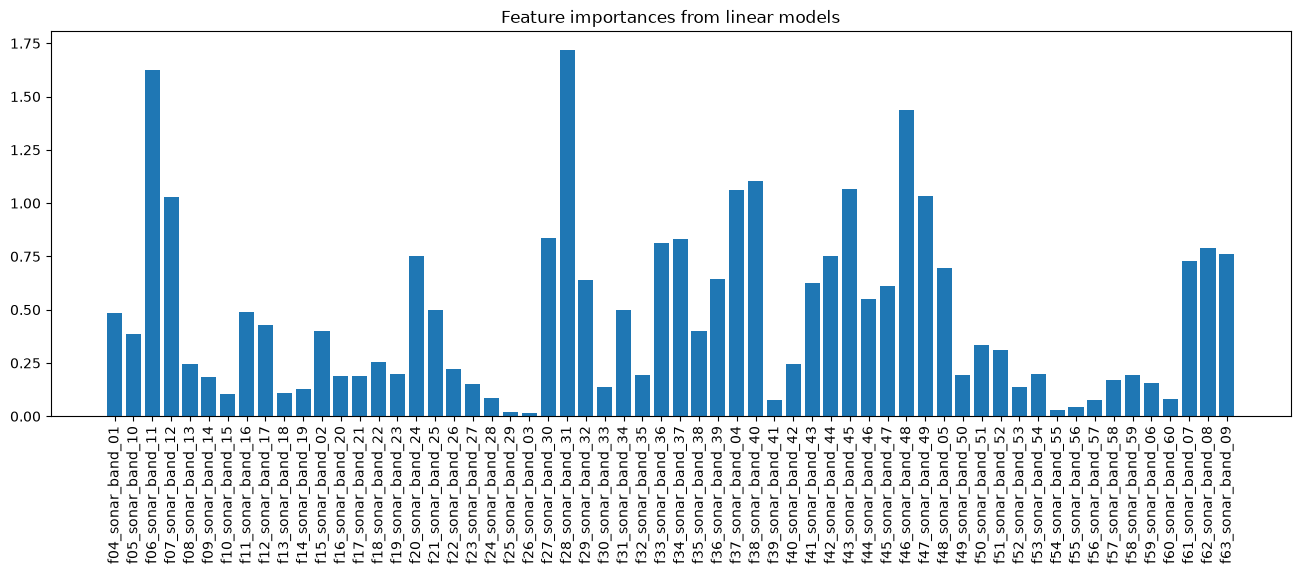

In [28]:
# Load the numerical, visualization, and machine-learning utilities for this workflow.
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectFromModel

# Can use feature importances as exploratory tool.
linear_svm = LinearSVC(random_state=43)
linear_svm.fit(X, y)
importances = np.abs(linear_svm.coef_[0])
plt.figure(figsize=(16, 5))
plt.bar(height=importances, x=X.columns)
plt.title("Feature importances from linear models")
plt.xticks(rotation=90)
plt.show()

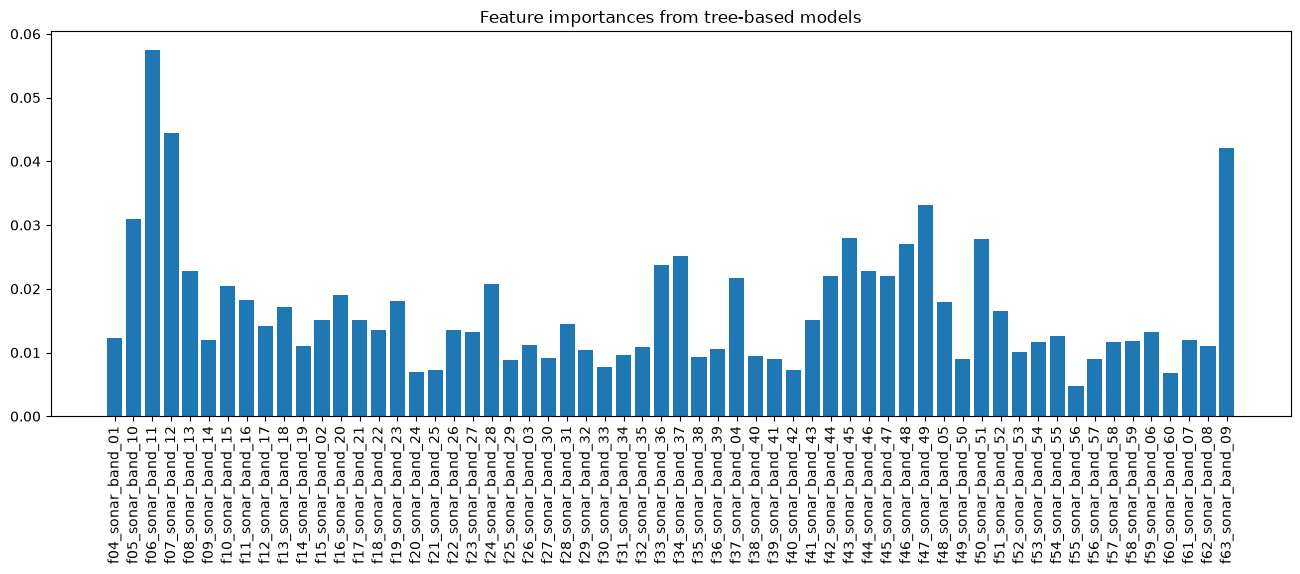

In [29]:
# Fit the configured model with its existing parameters.
# Can use feature importances as exploratory tool.
rf = RandomForestClassifier(criterion='entropy', random_state=43)
rf.fit(X, y)
importances = np.abs(rf.feature_importances_)
plt.figure(figsize=(16, 5))
plt.bar(height=importances, x=X.columns)
plt.title("Feature importances from tree-based models")
plt.xticks(rotation=90)
plt.show()

In [30]:
# Inspect or update the intermediate result produced by the preceding step.
# Alternatively, we can create a dataframe with certain attributes and score.
attr_scores = pd.DataFrame({"attribute": X.columns, "weight": rf.feature_importances_})
attr_scores.sort_values(by='weight', ascending=False)

,attribute,weight
2,f06_sonar_band_11,0.057532
3,f07_sonar_band_12,0.044394
59,f63_sonar_band_09,0.042132
43,f47_sonar_band_49,0.033155
1,f05_sonar_band_10,0.031000
39,f43_sonar_band_45,0.028047
46,f50_sonar_band_51,0.027842
42,f46_sonar_band_48,0.027083
30,f34_sonar_band_37,0.025110
29,f33_sonar_band_36,0.023701


In [31]:
# Evaluate the current estimator using the configured cross-validation strategy.
# We can use SelectFromModel to retain only important features.
# 1. linear.
linear_selector = SelectFromModel(linear_svm)
linear_X = linear_selector.fit_transform(X_train, y_train)
selected_features = [col for index, col in enumerate(X_train.columns)
            if index in linear_selector.get_support(indices=True)]
linear_X = pd.DataFrame(linear_X, columns=selected_features)
ad.report_classification_cv(linear_X, y_train, linear_svm)
y_pred = linear_svm.predict(X_test[linear_X.columns])
print(classification_report(y_test, y_pred))
print(linear_X.columns, len(linear_X.columns))

Mean Accuracy is 81.91 +/- 6.68
Mean Precision is 81.86 +/- 6.74
Mean Recall is 81.73 +/- 6.67
Mean F-score is 81.73 +/- 6.69
              precision    recall  f1-score   support

        Mine       0.76      0.80      0.78        20
        Rock       0.81      0.77      0.79        22

    accuracy                           0.79        42
   macro avg       0.79      0.79      0.79        42
weighted avg       0.79      0.79      0.79        42

Index(['f04_sonar_band_01', 'f06_sonar_band_11', 'f07_sonar_band_12',
       'f08_sonar_band_13', 'f17_sonar_band_21', 'f20_sonar_band_24',
       'f21_sonar_band_25', 'f28_sonar_band_31', 'f29_sonar_band_32',
       'f31_sonar_band_34', 'f33_sonar_band_36', 'f34_sonar_band_37',
       'f36_sonar_band_39', 'f37_sonar_band_04', 'f38_sonar_band_40',
       'f41_sonar_band_43', 'f42_sonar_band_44', 'f43_sonar_band_45',
       'f44_sonar_band_46', 'f46_sonar_band_48', 'f47_sonar_band_49',
       'f61_sonar_band_07', 'f62_sonar_band_08', 'f63_son

In [32]:
# Evaluate the current estimator using the configured cross-validation strategy.
# We can use SelectFromModel to retain only important features.
# 2. tree based.
tree_selector = SelectFromModel(rf)
tree_X = tree_selector.fit_transform(X_train, y_train)
selected_features = [col for index, col in enumerate(X_train.columns)
            if index in tree_selector.get_support(indices=True)]
tree_X = pd.DataFrame(tree_X, columns=selected_features)
ad.report_classification_cv(tree_X, y_train, rf)
y_pred = rf.predict(X_test[tree_X.columns])
print(classification_report(y_test, y_pred))
print(tree_X.columns, len(tree_X.columns))

Mean Accuracy is 81.35 +/- 4.69
Mean Precision is 81.65 +/- 4.41
Mean Recall is 80.89 +/- 5.07
Mean F-score is 80.94 +/- 5.00
              precision    recall  f1-score   support

        Mine       0.76      0.80      0.78        20
        Rock       0.81      0.77      0.79        22

    accuracy                           0.79        42
   macro avg       0.79      0.79      0.79        42
weighted avg       0.79      0.79      0.79        42

Index(['f05_sonar_band_10', 'f06_sonar_band_11', 'f07_sonar_band_12',
       'f08_sonar_band_13', 'f12_sonar_band_17', 'f24_sonar_band_28',
       'f28_sonar_band_31', 'f34_sonar_band_37', 'f41_sonar_band_43',
       'f43_sonar_band_45', 'f44_sonar_band_46', 'f45_sonar_band_47',
       'f47_sonar_band_49', 'f50_sonar_band_51', 'f51_sonar_band_52',
       'f63_sonar_band_09'],
      dtype='str') 16


In [33]:
# Inspect or update the intermediate result produced by the preceding step.
# Optional comparison: review this configuration against the original baseline.
# Context of both classification and regression.

### Recursive feature elimination

The optional example repeatedly removes the least relevant features according to a fitted model. Re-evaluate the reduced feature set using a consistent validation strategy.

In [34]:
# Load the numerical, visualization, and machine-learning utilities for this workflow.
# 3. recursive feature selection with LogisticRegression as exploratory tool.
# We specify step = 1, so that removes 1 feature in each iteration.
from sklearn.feature_selection import RFECV
rfs = RFECV(LogisticRegression(random_state=43), step=1)
rfs_X = rfs.fit_transform(X, y)
print(rfs_X.shape)

(208, 6)


In [35]:
# Continue the analysis using the original transformation and model parameters.
features_ranks = zip(rfs.get_feature_names_out(), rfs.ranking_)
for feature, rank in features_ranks:
  print(feature, '-', rank)

f06_sonar_band_11 - 33
f07_sonar_band_12 - 4
f33_sonar_band_36 - 1
f42_sonar_band_44 - 1
f43_sonar_band_45 - 16
f44_sonar_band_46 - 54


## 5. Class weighting

Explore how learner weights affect errors on minority classes. Use class-level metrics alongside overall accuracy when comparing the original configurations.

In [36]:
# Load the project dataset from its local data directory and inspect its schema.
cancer = pd.read_csv('data/cell_sample_measurements.csv')
cancer.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   f78_sample_record_id                  569 non-null    int64  
 1   f74_sample_diagnosis                  569 non-null    str    
 2   f82_radius_average                    569 non-null    float64
 3   f91_texture_average                   569 non-null    float64
 4   f79_perimeter_average                 569 non-null    float64
 5   f01_area_average                      569 non-null    float64
 6   f85_smoothness_average                569 non-null    float64
 7   f65_compactness_average               569 non-null    float64
 8   f71_concavity_average                 569 non-null    float64
 9   f68_concave_points_average            569 non-null    float64
 10  f88_symmetry_average                  569 non-null    float64
 11  f75_fractal_dimension_average 

<Axes: xlabel='f74_sample_diagnosis'>

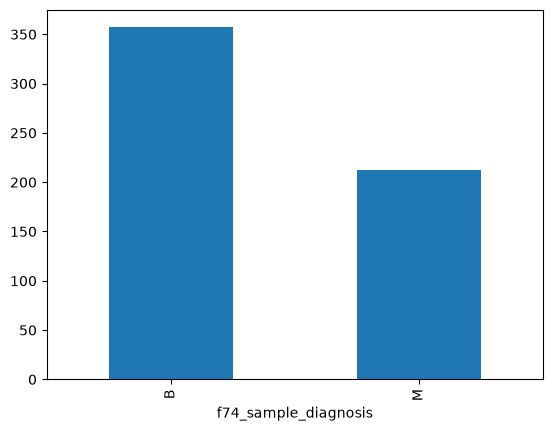

In [37]:
# Inspect or update the intermediate result produced by the preceding step.
# Visualise class imbalance.
cancer.f74_sample_diagnosis.value_counts().plot.bar()

In [38]:
# Create the predefined training and validation partitions without changing split parameters.
X = cancer[cancer.columns.difference(['f74_sample_diagnosis', 'f78_sample_record_id'])]
y = cancer[['f74_sample_diagnosis']]
y_encoded = y.apply(LabelEncoder().fit_transform)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=43)
y_train_encoded, y_test_encoded = train_test_split(y_encoded, test_size=0.2, random_state=43)

In [39]:
# Load the numerical, visualization, and machine-learning utilities for this workflow.
# 1.1 using xgboost default 'scale_pos_weight'.
import xgboost as xgb
xgb_clf = xgb.XGBClassifier(n_estimators=1, num_boost_rounds=1)
ad.report_classification_cv(X_train, y_train_encoded, xgb_clf)
cross_validation_predictions = cross_val_predict(xgb_clf, X_test, y_test_encoded)
print(classification_report(y_test_encoded, cross_validation_predictions))

Mean Accuracy is 91.21 +/- 2.20
Mean Precision is 91.63 +/- 2.10
Mean Recall is 89.77 +/- 2.85
Mean F-score is 90.44 +/- 2.54
              precision    recall  f1-score   support

           0       0.96      0.99      0.97        75
           1       0.97      0.92      0.95        39

    accuracy                           0.96       114
   macro avg       0.97      0.95      0.96       114
weighted avg       0.97      0.96      0.96       114



In [40]:
# Evaluate the current estimator using the configured cross-validation strategy.
# 1.2 set xgboost 'scale_pos_weight' to number_of_negative_rows/number_of_positive_rows.
class_ratio = np.sum(y_encoded == 0)/np.sum(y_encoded == 1)
xgb_clf = xgb.XGBClassifier(n_estimators=1, num_boost_rounds=1,
                            scale_pos_weight=float(class_ratio))
ad.report_classification_cv(X_train, y_train_encoded, xgb_clf)
cross_validation_predictions = cross_val_predict(xgb_clf, X_test, y_test_encoded)
print(classification_report(y_test_encoded, cross_validation_predictions))

Mean Accuracy is 92.75 +/- 2.47
Mean Precision is 92.40 +/- 2.39
Mean Recall is 92.37 +/- 3.02
Mean F-score is 92.28 +/- 2.70
              precision    recall  f1-score   support

           0       0.96      0.99      0.97        75
           1       0.97      0.92      0.95        39

    accuracy                           0.96       114
   macro avg       0.97      0.95      0.96       114
weighted avg       0.97      0.96      0.96       114



In [41]:
# Load the numerical, visualization, and machine-learning utilities for this workflow.
# Search for the best ratio of class weight using grid search.
from sklearn.model_selection import GridSearchCV
params = {'scale_pos_weight': [class_ratio, 0.5, 1, 10, 25, 50, 75, 99, 100, 1000] }
xgb_clf = xgb.XGBClassifier(n_estimators=1, num_boost_rounds=1)
grid_search = GridSearchCV(xgb_clf, param_grid=params)
grid_search.fit(X_train, y_train_encoded)
print(grid_search.best_params_)

{'scale_pos_weight': np.float64(1.6839622641509433)}


In [42]:
# Inspect or update the intermediate result produced by the preceding step.
# Optional comparison: review this configuration against the original baseline.

In [43]:
# Evaluate the current estimator using the configured cross-validation strategy.
# 2.1 using default class weights with svm.
svm = SVC(random_state=43)
ad.report_classification_cv(X_train, y_train, svm)
cross_validation_predictions = cross_val_predict(svm, X_test, y_test)
print(classification_report(y_test, cross_validation_predictions))

Mean Accuracy is 89.67 +/- 2.66
Mean Precision is 91.71 +/- 2.36
Mean Recall is 86.97 +/- 3.40
Mean F-score is 88.41 +/- 3.17
              precision    recall  f1-score   support

           B       0.91      1.00      0.96        75
           M       1.00      0.82      0.90        39

    accuracy                           0.94       114
   macro avg       0.96      0.91      0.93       114
weighted avg       0.94      0.94      0.94       114



In [44]:
# Evaluate the current estimator using the configured cross-validation strategy.
# 2.2 using 'balanced' with svm.
svm = SVC(class_weight='balanced', random_state=43)
ad.report_classification_cv(X_train, y_train, svm)
cross_validation_predictions = cross_val_predict(svm, X_test, y_test)
print(classification_report(y_test, cross_validation_predictions))

Mean Accuracy is 89.23 +/- 4.98
Mean Precision is 89.12 +/- 5.87
Mean Recall is 88.19 +/- 4.72
Mean F-score is 88.52 +/- 5.22
              precision    recall  f1-score   support

           B       0.95      0.96      0.95        75
           M       0.92      0.90      0.91        39

    accuracy                           0.94       114
   macro avg       0.93      0.93      0.93       114
weighted avg       0.94      0.94      0.94       114

